<img src="https://raw.githubusercontent.com/telmomm/CERTA/main/docs/assets/logo/certa-logo.png" alt="CERTA" width="220">

# T1.1 · Benchmark circuits

*Netlists, tolerances, fault universe and starting simulations of the three benchmark circuits*

Loads the netlists of the benchmark circuits described in `circuits.md`, checks their nominal response against the published specification, builds their fault universe with spicefault and runs a first Monte Carlo with the tolerances of the source. The four-op-amp biquad is not here yet: its netlist is pending (see `circuits.md`).

- **Input:** `netlists/*.cir`.
- **Output:** `fault_universe.csv` (one row per fault, with whether the source paper uses it) and `starting_simulations.csv` (per fault, the share of drawn circuits whose response leaves the fault-free band).
- **To re-run:** run all cells. The seed is fixed, so it gives the same result if run twice. It takes about a minute.
- **Environment:** the repository `.venv` (see `CONTRIBUTING.md`) and ngspice.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spicefault
from spicefault import Circuit, Experiment, SimulationConfig, Simulator
from spicefault.faults import FaultRule, FaultUniverse, ParametricFault, open_rule, short_rule, parametric_rule
from spicefault.variation import NormalVariation, VariationSet, tolerances

pd.set_option("display.max_colwidth", 90)
CERTA = {"navy": "#0B2D4A", "teal": "#00BFA5", "blue": "#00AEEF", "sky": "#A7E3F7", "ice": "#E6EEF6"}

class table:
    """Shows a DataFrame with the CERTA colours in the notebook and as a LaTeX table in the PDF export.
    `bar` is a numeric column drawn as bars."""
    def __init__(self, df, bar=None):
        self.df, self.bar = df, bar
    def _repr_html_(self):
        styler = self.df.style.hide(axis="index").set_table_styles([
            {"selector": "th", "props": f"background-color: {CERTA['navy']}; color: white; text-align: left;"},
            {"selector": "tbody tr:nth-child(even)", "props": f"background-color: {CERTA['ice']};"},
        ])
        if self.bar is not None:
            styler = styler.bar(subset=[self.bar], color=CERTA["teal"], vmin=0)
        return styler.to_html()
    def _repr_latex_(self):
        return self.df.style.hide(axis="index").format(precision=3).to_latex(hrules=True)
    def __repr__(self):
        return self.df.to_string(index=False)

NETLISTS = Path("netlists")
UNIVERSE = Path("fault_universe.csv")
STARTING = Path("starting_simulations.csv")

SEED = 2027
HEALTHY_SAMPLES = 500  # fault-free circuits drawn within tolerance
FAULT_SAMPLES = 20     # circuits drawn per fault
WORKERS = 4
print("spicefault", spicefault.__version__)

spicefault 0.4.1


## 1. Circuits

Each circuit with the node read as its output, the AC sweep and the source of its tolerances and faults. Only the top level of the netlist is exposed to spicefault: the elements inside the op-amp subcircuits are not addressable, which is what is wanted at board level.

In [2]:
CIRCUITS = {
    "sallen_key_bandpass": {"file": "sallen_key_bandpass.cir", "output": "v(out)", "sweep": "ac dec 50 1k 1meg"},
    "leapfrog_lowpass": {"file": "leapfrog_lowpass.cir", "output": "v(19)", "sweep": "ac dec 50 10 100k"},
}
for name, spec in CIRCUITS.items():
    spec["circuit"] = Circuit.from_netlist(NETLISTS / spec["file"], name=name)
    spec["config"] = SimulationConfig(analyses=(spec["sweep"],), outputs=("frequency", spec["output"]))
    problems = [p for p in spec["circuit"].check() if "subcircuit element" not in p]
    print(f"{name}: {len(spec['circuit'].components())} top-level elements, problems: {problems or 'none'}")

table(pd.DataFrame([
    {"circuit": name, "component": c.name, "nodes": " ".join(c.nodes), "value": c.parameters.get("value", ""), "model": c.model}
    for name, spec in CIRCUITS.items() for c in spec["circuit"].components() if c.kind in "RC"
]))

sallen_key_bandpass: 9 top-level elements, problems: none
leapfrog_lowpass: 26 top-level elements, problems: none


circuit,component,nodes,value,model
sallen_key_bandpass,R1,in a,1000.000000,
sallen_key_bandpass,R2,a out,3000.000000,
sallen_key_bandpass,C1,a 0,0.000000,
sallen_key_bandpass,C2,a b,0.000000,
sallen_key_bandpass,R3,b 0,2000.000000,
sallen_key_bandpass,R4,n 0,4000.000000,
sallen_key_bandpass,R5,out n,4000.000000,
leapfrog_lowpass,R1,20 2,10000.000000,
leapfrog_lowpass,R2,2 4,10000.000000,
leapfrog_lowpass,R3,10 2,10000.000000,


## 2. Nominal response

The nominal circuit, without tolerances or faults, against the specification of the source. For the band-pass the centre frequency is where the phase crosses zero; for the low-pass the cut-off is where the gain falls 3 dB below its DC value. The ITC'97 benchmark gives no numeric specification for the leapfrog.

In [3]:
def response(spec, netlist=None):
    """Frequency and gain in dB of one simulation of the circuit."""
    result = Simulator().run(netlist or spec["circuit"].to_netlist(), spec["config"])
    plot = result.plot("ac")
    return plot["frequency"].real, plot[spec["output"]]

def crossing(f, y, level):
    """First frequency at which y crosses level, interpolated on a log axis."""
    i = np.flatnonzero(np.diff(np.sign(y - level)))[0]
    return float(10 ** np.interp(level, [y[i], y[i + 1]], np.log10(f[i:i + 2])) if y[i] < y[i + 1]
                 else 10 ** np.interp(level, [y[i + 1], y[i]], np.log10(f[i:i + 2])[::-1]))

f, v = response(CIRCUITS["sallen_key_bandpass"])
g = 20 * np.log10(abs(v))
centre = crossing(f, np.angle(v), 0.0)
low, high = crossing(f, g, g.max() - 3), crossing(f[g.argmax():], g[g.argmax():], g.max() - 3)
lf, lv = response(CIRCUITS["leapfrog_lowpass"])
lg = 20 * np.log10(abs(lv))
nominal = pd.DataFrame([
    ["sallen_key_bandpass", "centre frequency (kHz)", centre / 1e3, 25.0],
    ["sallen_key_bandpass", "gain at centre (dB)", g.max(), None],
    ["sallen_key_bandpass", "Q", centre / (high - low), None],
    ["leapfrog_lowpass", "DC gain (dB)", lg[0], None],
    ["leapfrog_lowpass", "cut-off frequency (kHz)", crossing(lf, lg, lg[0] - 3) / 1e3, None],
], columns=["circuit", "feature", "simulated", "published"]).round(2)
table(nominal)

circuit,feature,simulated,published
sallen_key_bandpass,centre frequency (kHz),25.600000,25.000000
sallen_key_bandpass,gain at centre (dB),1.580000,nan
sallen_key_bandpass,Q,0.490000,nan
leapfrog_lowpass,DC gain (dB),-7.100000,nan
leapfrog_lowpass,cut-off frequency (kHz),1.350000,nan


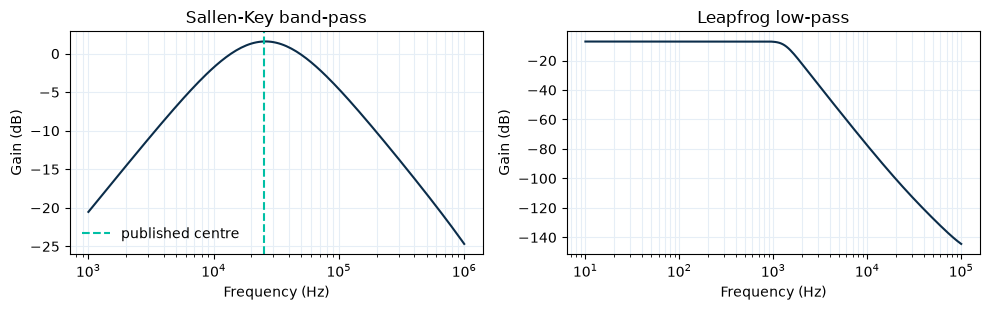

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, (freq, gain, title) in zip(axes, [(f, g, "Sallen-Key band-pass"), (lf, lg, "Leapfrog low-pass")]):
    ax.semilogx(freq, gain, color=CERTA["navy"])
    ax.set(title=title, xlabel="Frequency (Hz)", ylabel="Gain (dB)")
    ax.grid(True, which="both", color=CERTA["ice"])
axes[0].axvline(25e3, color=CERTA["teal"], ls="--", label="published centre")
axes[0].legend(frameon=False)
fig.tight_layout()

## 3. Fault universe

Open (100 MΩ in series), short (1 Ω in parallel) and a high and a low parametric fault on every resistor and capacitor. Parametric faults are ± 50 % for the Sallen-Key and ± 6σ for the leapfrog. The column `reference` marks the faults the source paper simulates: R2, R3, C1 and C2 parametric for the Sallen-Key, all of them for the leapfrog. Op-amps carry no faults (see `circuits.md`).

In [5]:
def flag(names=None):
    """Tag `reference = y` on the listed components, or on all of them."""
    return lambda c: {"reference": "y" if names is None or c.name in names else "n"}

# Sallen-Key: tolerances and faults of Aminian et al.
sk = CIRCUITS["sallen_key_bandpass"]
sk["universe"] = FaultUniverse(sk["circuit"], [
    open_rule("RC", r_open=1e8, tags=flag(())),
    short_rule("RC", r_short=1.0, tags=flag(())),
    parametric_rule((-0.5, 0.5), "RC", tags=flag(("R2", "R3", "C1", "C2"))),
])
sk["variations"] = tolerances(sk["circuit"], {"R": 0.05, "C": 0.10})

# Leapfrog: sigma of Kondagunturi et al.; tolerance up to 3 sigma, parametric faults at 6 sigma
lfg = CIRCUITS["leapfrog_lowpass"]
SIGMA = {c.name: 0.03 if c.name == "C4" else 0.02 for c in lfg["circuit"].components() if c.kind in "RC"}
six_sigma = FaultRule("parametric", lambda c: [ParametricFault(c.name, deviation=d * 6 * SIGMA[c.name]) for d in (-1, 1)],
                      "RC", tags=flag())
lfg["universe"] = FaultUniverse(lfg["circuit"], [
    open_rule("RC", r_open=1e8, tags=flag()), short_rule("RC", r_short=1.0, tags=flag()), six_sigma])
lfg["variations"] = VariationSet([
    NormalVariation(name, None, sigma=lfg["circuit"].component(name).parameters["value"] * s, truncate=3)
    for name, s in SIGMA.items()])

universe = pd.DataFrame([
    {"circuit": name, "fault_id": fault.fault_id, "component": fault.components[0], "fault_type": fault.fault_type,
     "deviation": (fault.metadata()["magnitude"] or {}).get("value", ""), "reference": fault.tags["reference"]}
    for name, spec in CIRCUITS.items() for fault in spec["universe"].selected()])
universe.to_csv(UNIVERSE, index=False, encoding="utf-8")
table(universe.groupby(["circuit", "fault_type"]).agg(faults=("fault_id", "size"),
      reference=("reference", lambda r: (r == "y").sum())).reset_index())

circuit,fault_type,faults,reference
leapfrog_lowpass,open_circuit,17,17
leapfrog_lowpass,parametric,34,34
leapfrog_lowpass,short_circuit,17,17
sallen_key_bandpass,open_circuit,7,0
sallen_key_bandpass,parametric,14,8
sallen_key_bandpass,short_circuit,7,0


## 4. Starting simulations

A first Monte Carlo with the tolerances of each source: fault-free circuits and circuits drawn per fault. The fault-free band is the range of the gain over the fault-free circuits at each frequency; a drawn faulty circuit is counted as outside when its gain leaves that band at some frequency of the sweep. This is only a check that the faults are visible with the whole response observed: the detection metrics with intervals are T1.4.

In [6]:
runs = {}
for name, spec in CIRCUITS.items():
    experiment = Experiment(spec["circuit"], config=spec["config"], faults=list(spec["universe"].selected()),
                            variations=spec["variations"], samples=FAULT_SAMPLES,
                            healthy_samples=HEALTHY_SAMPLES, seed=SEED)
    result = experiment.run(workers=WORKERS)
    print(name, result.status_counts())
    runs[name] = result

sallen_key_bandpass {'SUCCESS': 1060}


leapfrog_lowpass {'SUCCESS': 1860}


In [7]:
def gains(result, output):
    """Fault id and gain in dB per successful sample, and the frequency axis."""
    ok = [s for s in result if s.result.ok]
    freq = ok[0].result.plot("ac")["frequency"].real
    gain = np.array([20 * np.log10(abs(s.result.plot("ac")[output])) for s in ok])
    return np.array([s.fault_id for s in ok]), freq, gain

rows, bands = [], {}
for name, spec in CIRCUITS.items():
    ids, freq, gain = gains(runs[name], spec["output"])
    healthy = gain[ids == "healthy"]
    lo, hi = healthy.min(axis=0), healthy.max(axis=0)
    bands[name] = (freq, lo, hi, ids, gain)
    planned = pd.Series([s.fault_id for s in runs[name]]).value_counts()
    for fault in universe[universe.circuit == name].itertuples():
        g = gain[ids == fault.fault_id]
        outside = ((g < lo) | (g > hi)).any(axis=1)
        rows.append({"circuit": name, "fault_id": fault.fault_id, "fault_type": fault.fault_type,
                     "reference": fault.reference, "samples": int(planned[fault.fault_id]),
                     "failed": int(planned[fault.fault_id] - len(g)), "outside_band": round(float(outside.mean()), 3)})
starting = pd.DataFrame(rows)
starting.to_csv(STARTING, index=False, encoding="utf-8")
table(starting.groupby(["circuit", "fault_type"]).agg(
    faults=("fault_id", "size"), failed=("failed", "sum"), mean_outside_band=("outside_band", "mean")).round(3).reset_index(),
    bar="mean_outside_band")

circuit,fault_type,faults,failed,mean_outside_band
leapfrog_lowpass,open_circuit,17,0,1.000000
leapfrog_lowpass,parametric,34,0,0.259000
leapfrog_lowpass,short_circuit,17,0,1.000000
sallen_key_bandpass,open_circuit,7,0,1.000000
sallen_key_bandpass,parametric,14,0,0.939000
sallen_key_bandpass,short_circuit,7,0,1.000000


Faults that stay inside the fault-free band in some of their drawn circuits: these are the ones whose detection depends on the tolerances, and the first candidates for ambiguity groups.

In [8]:
table(starting[starting.outside_band < 1].sort_values(["circuit", "outside_band"]), bar="outside_band")

circuit,fault_id,fault_type,reference,samples,failed,outside_band
leapfrog_lowpass,R13:parametric:+0.12,parametric,y,20,0,0.050000
leapfrog_lowpass,C3:parametric:-0.12,parametric,y,20,0,0.050000
leapfrog_lowpass,R2:parametric:+0.12,parametric,y,20,0,0.100000
leapfrog_lowpass,R3:parametric:-0.12,parametric,y,20,0,0.100000
leapfrog_lowpass,R3:parametric:+0.12,parametric,y,20,0,0.100000
leapfrog_lowpass,R4:parametric:+0.12,parametric,y,20,0,0.100000
leapfrog_lowpass,R6:parametric:+0.12,parametric,y,20,0,0.100000
leapfrog_lowpass,C1:parametric:+0.12,parametric,y,20,0,0.100000
leapfrog_lowpass,C2:parametric:+0.12,parametric,y,20,0,0.100000
leapfrog_lowpass,C3:parametric:+0.12,parametric,y,20,0,0.100000


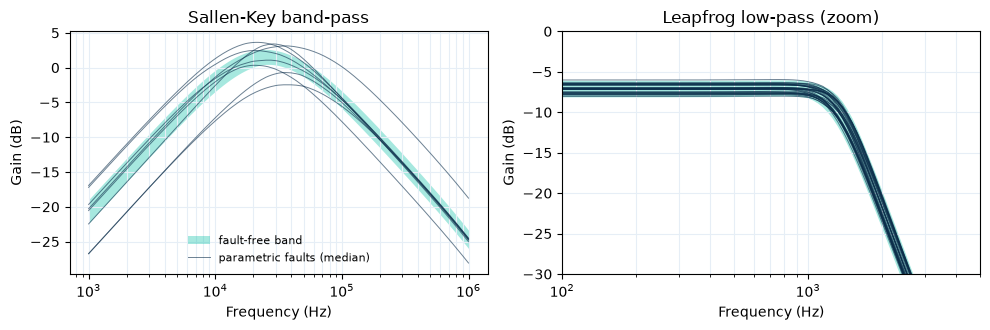

In [9]:
TITLES = {"sallen_key_bandpass": "Sallen-Key band-pass", "leapfrog_lowpass": "Leapfrog low-pass (zoom)"}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, (name, (freq, lo, hi, ids, gain)) in zip(axes, bands.items()):
    ax.fill_between(freq, lo, hi, color=CERTA["teal"], alpha=0.35, lw=0, label="fault-free band")
    reference = universe[(universe.circuit == name) & (universe.reference == "y") & (universe.fault_type == "parametric")]
    for i, fault in enumerate(reference.fault_id):
        ax.semilogx(freq, np.median(gain[ids == fault], axis=0), color=CERTA["navy"], lw=0.7, alpha=0.6,
                    label="parametric faults (median)" if i == 0 else None)
    ax.set_xscale("log")
    ax.set(title=TITLES[name], xlabel="Frequency (Hz)", ylabel="Gain (dB)")
    ax.grid(True, which="both", color=CERTA["ice"])
axes[0].legend(frameon=False, fontsize=8)
axes[1].set(xlim=(100, 5e3), ylim=(-30, 0))
fig.tight_layout()

## Conclusions and notes

- **The Sallen-Key reproduces its specification.** With the µA741-like macromodel the centre frequency is 25.6 kHz against the published 25 kHz, so values and topology are consistent. Its Q is low (about 0.5).
- **The leapfrog has no numeric specification to check against.** Its nominal DC gain is −7.1 dB and its cut-off 1.35 kHz; the comparison with the source is only the shape of its published response.
- **Fault universe:** 28 faults in the Sallen-Key (8 used by the source) and 68 in the leapfrog (all used by the source), in `fault_universe.csv`.
- **All 2920 starting simulations converge**, including the transistor-level op-amps of the leapfrog. Every open and short leaves the fault-free band in every drawn circuit.
- **The ± 6σ soft faults of the leapfrog are hard to see at the output.** On average only 26 % of their drawn circuits leave the fault-free band, against 94 % for the ± 50 % faults of the Sallen-Key. With 17 components varying at the same time, a 6σ deviation of a single one stays within the fault-free spread. This matters for E1 and E5: the standard soft faults of the benchmark are not detectable faults by construction.

### Notes

- `outside_band` is a sanity check on 20 circuits per fault with the whole response observed, not a detection probability. The metrics with intervals are T1.4.
- Pending: the netlist of the four-op-amp biquad, and checking the Sallen-Key values and its ± 50 % against the original papers (see `circuits.md`).